In [1]:
!pip install segment-geospatial  leafmap localtileserver
!pip install rasterio
!pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 732.8/732.8 kB 13.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 91.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 64.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 155.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 155.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 154.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 91.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 593.1/593.1 kB 33.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 81.8 MB/s  0:00:00
  Attempting uninstall: duckdb
    Found existing installation: duckdb 1.3.2
    Uninstalling duckdb-1.3.2:
      Successfully uninstalled duckdb-1.3.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47/47 [leafmap]


In [2]:
# connect my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:

path = '/content/drive/MyDrive/dataset/im.tif'

In [4]:
import os
import leafmap
import torch
from samgeo import SamGeo
from samgeo.common import tms_to_geotiff, get_basemaps
import rasterio
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [5]:
src = rasterio.open(path)
img = src.read()
img.shape

(5, 2048, 2048)

In [6]:
img = img.transpose([1,2,0])
img = img.astype('uint8')

(np.float64(-0.5), np.float64(2047.5), np.float64(2047.5), np.float64(-0.5))

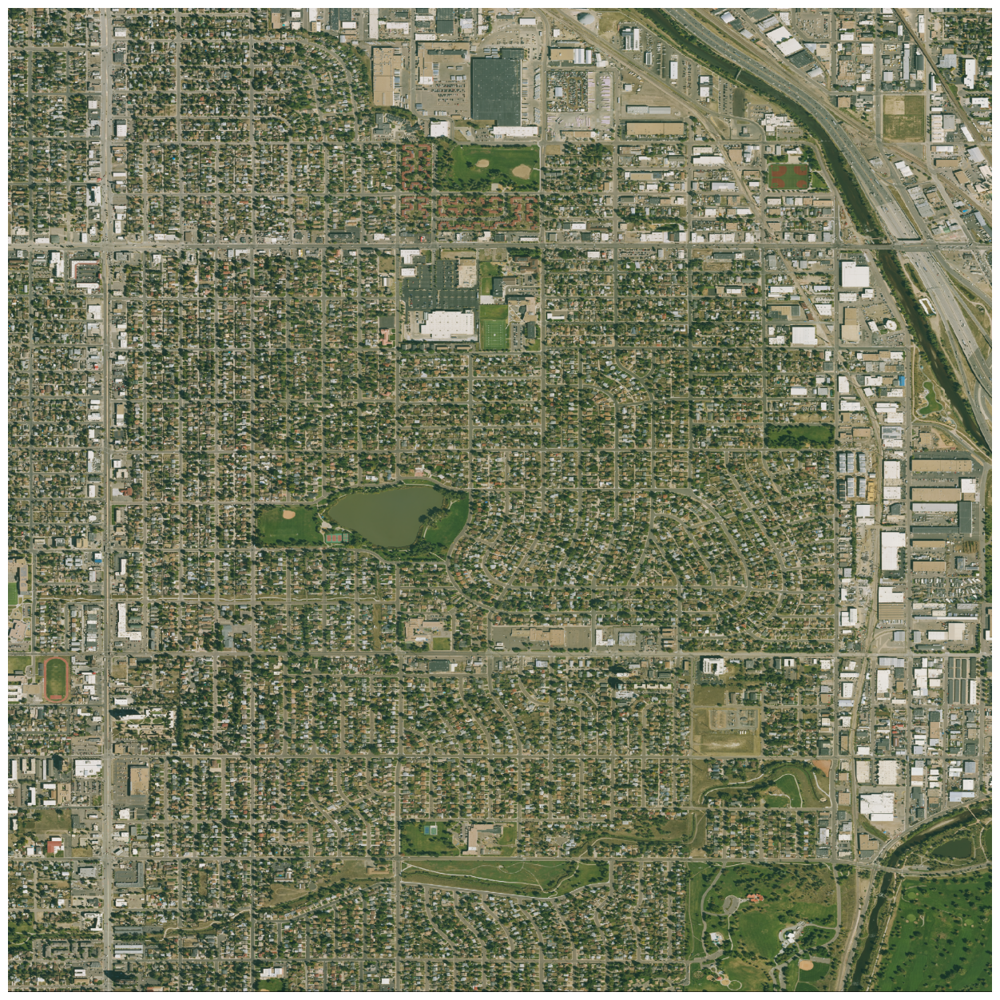

In [7]:
img_rgb= img[:, :, [0, 1, 2]]
plt.figure(figsize=[16,16])
plt.imshow(img_rgb)
plt.axis('off')

In [8]:
# CHANGED: keep only 3 bands (RGB), 8-bit, full resolution (no downscale)
with rasterio.open(path) as s:
    print("bands:", s.count, "dtypes:", s.dtypes)
    rgb = s.read([1, 2, 3])
    prof = s.profile

prof.update(count=3, dtype='uint8', driver='GTiff')
for k in ('blockxsize', 'blockysize', 'tiled', 'compress'):
    prof.pop(k, None)   # removes the BLOCKXSIZE warning

with rasterio.open('/content/RGB.tif', 'w', **prof) as dst:
    dst.write(rgb.astype('uint8'))

bands: 5 dtypes: ('uint8', 'uint8', 'uint8', 'uint8', 'uint8')


In [9]:
# CHANGED: checkpoint path removed, samgeo downloads/caches it by itself
print("CUDA available:", torch.cuda.is_available())   # must be True, otherwise Runtime > Change runtime type > T4 GPU

CUDA available: True


In [10]:
# CHANGED: no erosion, tuned mask generator parameters
device = "cuda" if torch.cuda.is_available() else "cpu"
sam = SamGeo(
    model_type="vit_h",          # use "vit_b" if you want it much faster
    device=device,
    sam_kwargs={
        "points_per_side": 32,
        "pred_iou_thresh": 0.88,
        "stability_score_thresh": 0.92,
        "min_mask_region_area": 50,
    },
)

Model checkpoint for vit_h not found.


Downloading...
From: https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
To: /root/.cache/torch/hub/checkpoints/sam_vit_h_4b8939.pth
100%|██████████| 2.56G/2.56G [00:15<00:00, 170MB/s] 


In [11]:
image = '/content/RGB.tif'   # CHANGED: the clean 3-band image

In [12]:
mask = 'segment.tif'
sam.generate(image, mask, batch=True, unique=True)   # CHANGED: unique=True, no mask_multiplier

100%|██████████| 25/25 [04:11<00:00, 10.07s/it]


In [13]:

# NEW: check that SAM really produced several objects
with rasterio.open(mask) as m:
    a = m.read(1)
    u = np.unique(a)
    print("objects found:", len(u) - 1 if 0 in u else len(u))
    print("mask dtype:", a.dtype, "| first values:", u[:10])

objects found: 1
mask dtype: uint8 | first values: [  0 255]


In [14]:
if not os.path.isdir('/content/Result'):
  os.mkdir('/content/Result')

In [15]:
shapefile = '/content/Result/segment.shp'   # CHANGED: typo .sph -> .shp
sam.tiff_to_shp(mask, shapefile)

In [16]:
#visualising the result
src_test = rasterio.open(image)
correct_shapefile = '/content/Result/segment.shp'   # CHANGED
mask_result = gpd.read_file(correct_shapefile)
print("number of polygons:", len(mask_result))       # should be in the hundreds/thousands, not 1

number of polygons: 352


(np.float64(-105.028281),
 np.float64(-104.996497),
 np.float64(39.684778),
 np.float64(39.719611))

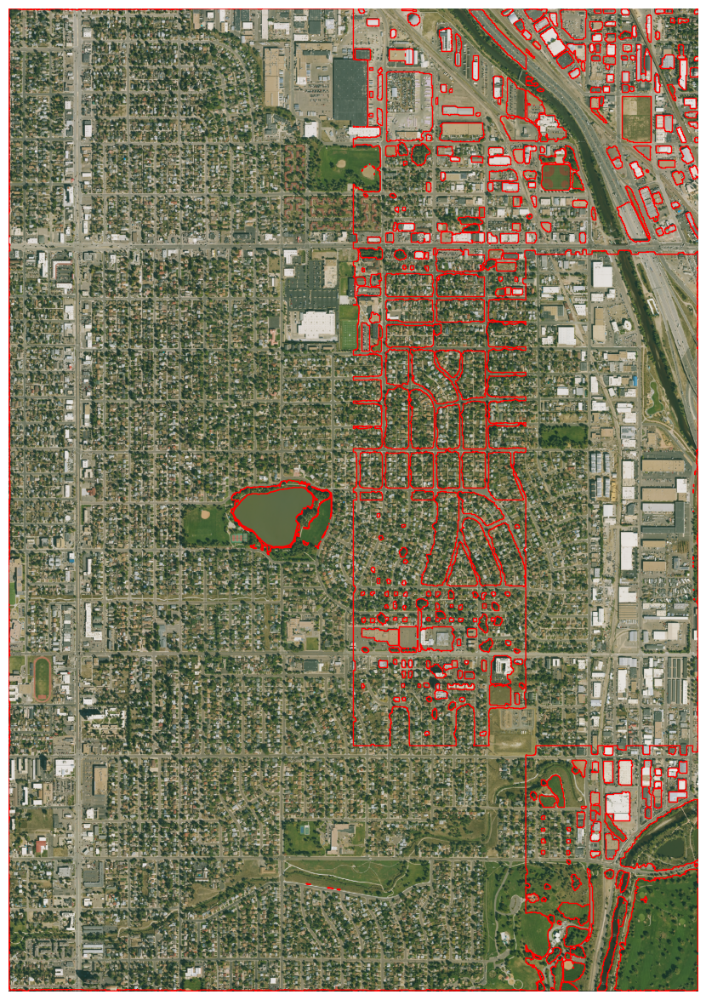

In [19]:
from rasterio.plot import show

fig, ax = plt.subplots(figsize=(15,15))
show(src_test, ax=ax)
mask_result.plot(ax=ax, facecolor='none', edgecolor='red')
plt.axis('off')

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

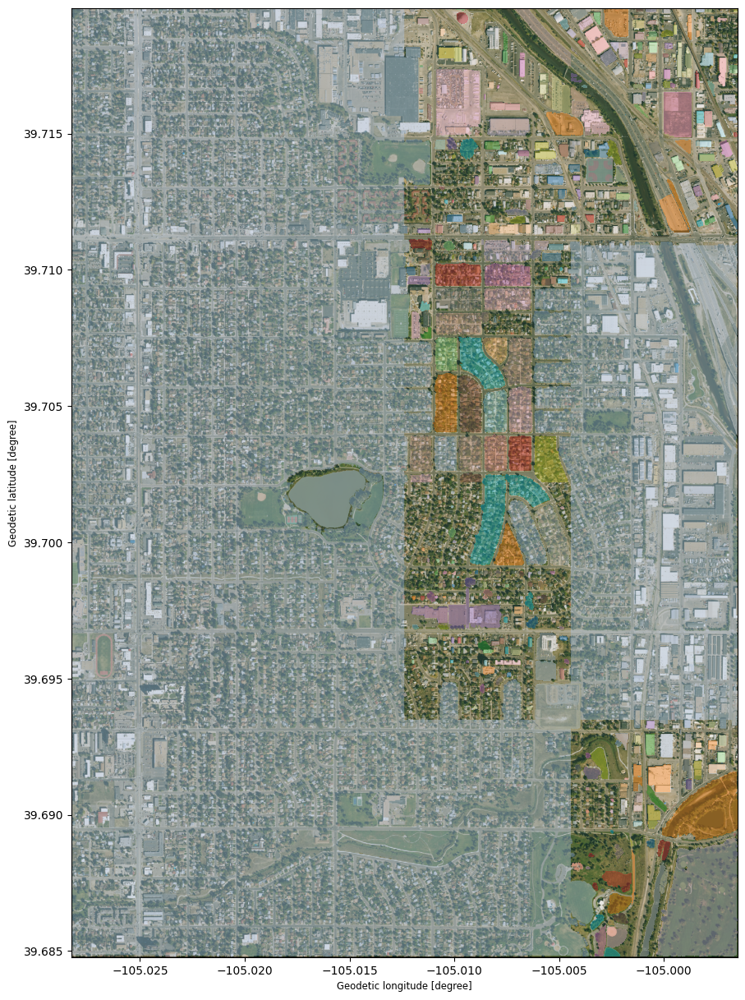

In [20]:
# CHANGED: unique ids (no duplicates) and a larger colormap
mask_result['id'] = np.random.permutation(len(mask_result))
fig, ax = plt.subplots(figsize=(15,15))
rasterio.plot.show(src_test, ax=ax)
mask_result.plot(ax=ax, column='id', cmap='tab20', alpha=0.4)

In [21]:
#download the result
!zip -r /content/Result.Zip /content/Result/
from google.colab import files
files.download("/content/Result.Zip")

  adding: content/Result/ (stored 0%)
  adding: content/Result/segment.shx (deflated 44%)
  adding: content/Result/segment.shp (deflated 77%)
  adding: content/Result/segment.cpg (stored 0%)
  adding: content/Result/segment.dbf (deflated 99%)
  adding: content/Result/segment.prj (deflated 17%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>